# Simplified Checkout A/B Test: Design, Decision Rules, and Simulation

> **SIMULATED EXPERIMENT DATA ONLY**
>
> No experiment was run. Historical GA4 aggregates are used only to
> plan a test. Every row generated later in this notebook has
> `is_simulated = True`.

**Decision question:** Should a simplified checkout replace the current
experience for eligible users?

This notebook sizes the test, audits whether its decision rule can
actually ship a change that meets the target, sizes the payment-error
guardrail, adds a four-look sequential monitoring plan, and demonstrates
the pre-registered analysis on one seeded synthetic experiment. A
favorable simulated result is not evidence that the product change
works.

## 1. Load governed planning aggregates

SQL remains the source of truth. The notebook selects the newest
complete aggregate export and never loads raw users, sessions, events,
transactions, or browsing paths.

In [1]:
%matplotlib inline

import json
from pathlib import Path
from math import ceil, erfc, floor, sqrt
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import brentq
from scipy.stats import multivariate_normal

ROOT = Path.cwd()
RESULT_ROOT = ROOT / "data" / "interim" / "query_results"
FIGURE_DIR = ROOT / "notebooks" / "figures"
OUTPUT_DIR = ROOT / "notebooks" / "outputs"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_FILES = [
    "01_metric_tree_summary.csv",
    "05_checkout_funnel.csv",
]
complete_exports = [
    path
    for path in RESULT_ROOT.iterdir()
    if path.is_dir()
    and all((path / filename).is_file() for filename in REQUIRED_FILES)
]
if not complete_exports:
    raise FileNotFoundError(
        "No complete aggregate export found. Run `make extract` first."
    )
EXPORT_DIR = sorted(complete_exports)[-1]

summary = pd.read_csv(
    EXPORT_DIR / "01_metric_tree_summary.csv"
).iloc[0]
checkout = pd.read_csv(EXPORT_DIR / "05_checkout_funnel.csv")

datasets = {
    "summary": pd.DataFrame([summary]),
    "checkout": checkout,
}
forbidden_identifier_columns = {
    "user_key",
    "session_key",
    "event_timestamp",
    "order_key",
    "transaction_id",
}
for name, frame in datasets.items():
    leaked = forbidden_identifier_columns.intersection(frame.columns)
    assert not leaked, f"{name} contains prohibited identifiers: {leaked}"

checkout_sessions = int(
    checkout.loc[
        checkout["stage_name"] == "begin_checkout", "sessions"
    ].iloc[0]
)
purchase_after_checkout_sessions = int(
    checkout["purchase_after_checkout_sessions"].iloc[0]
)
historical_baseline_proxy = (
    purchase_after_checkout_sessions / checkout_sessions
)
observed_days = int(summary["observed_calendar_days"])
average_order_value = float(summary["average_order_value_usd"])
daily_checkout_session_proxy = checkout_sessions / observed_days

assert checkout_sessions == 5_187
assert purchase_after_checkout_sessions == 2_491
assert observed_days == 92
assert abs(historical_baseline_proxy - 0.4802390591864276) < 1e-12

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
NAVY = "#17324D"
BLUE = "#2C7FB8"
TEAL = "#2A9D8F"
ORANGE = "#F4A261"
RED = "#D95F59"
GREY = "#7A8793"

print(f"Aggregate export: {EXPORT_DIR.name}")
print(
    f"Planning proxy: {purchase_after_checkout_sessions:,} / "
    f"{checkout_sessions:,} = {historical_baseline_proxy:.2%}"
)

Aggregate export: 20260731T052813Z
Planning proxy: 2,491 / 5,187 = 48.02%


## 2. Metric contract and historical baseline proxy

The historical rate is a **same-session checkout-session rate**. The
planned experiment uses a **user-randomized 24-hour outcome**. The
historical value is therefore a planning proxy, not a guaranteed
production baseline.

Follow-up aggregate query `11_checkout_telemetry_diagnostic.sql`
reconciles the historical paths and shows that all 941 purchases outside
the strict intermediate sequence contain shipping at or before the
governed checkout start and payment before purchase. Repeated checkout
entry—not missing all intermediate telemetry—creates the strict gap.

In [2]:
Z_95 = NormalDist().inv_cdf(0.975)

def wilson_interval(successes, trials, z=Z_95):
    successes = int(successes)
    trials = int(trials)
    if trials == 0:
        return (np.nan, np.nan)
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    center = (
        proportion + z**2 / (2 * trials)
    ) / denominator
    half_width = (
        z
        * sqrt(
            proportion * (1 - proportion) / trials
            + z**2 / (4 * trials**2)
        )
        / denominator
    )
    return max(0, center - half_width), min(1, center + half_width)

baseline_lower, baseline_upper = wilson_interval(
    purchase_after_checkout_sessions,
    checkout_sessions,
)
baseline_table = pd.DataFrame(
    [
        {
            "Planning input": "Ordered checkout sessions",
            "Value": f"{checkout_sessions:,}",
            "Use": "Eligibility-volume proxy",
        },
        {
            "Planning input": "Purchases after ordered checkout",
            "Value": f"{purchase_after_checkout_sessions:,}",
            "Use": "Primary-rate numerator proxy",
        },
        {
            "Planning input": "Historical completion proxy",
            "Value": f"{historical_baseline_proxy:.2%}",
            "Use": "Sample-size baseline",
        },
        {
            "Planning input": "95% Wilson interval",
            "Value": (
                f"{baseline_lower:.2%}–{baseline_upper:.2%}"
            ),
            "Use": "Baseline uncertainty sensitivity",
        },
        {
            "Planning input": "Checkout-session volume",
            "Value": f"{daily_checkout_session_proxy:.1f}/day",
            "Use": "Duration proxy only",
        },
        {
            "Planning input": "Clean historical AOV",
            "Value": f"${average_order_value:,.2f}",
            "Use": "Revenue scenario only",
        },
    ]
)
display(baseline_table)

,Planning input,Value,Use
0,Ordered checkout sessions,"5,187",Eligibility-volume proxy
1,Purchases after ordered checkout,"2,491",Primary-rate numerator proxy
2,Historical completion proxy,48.02%,Sample-size baseline
3,95% Wilson interval,46.67%–49.38%,Baseline uncertainty sensitivity
4,Checkout-session volume,56.4/day,Duration proxy only
5,Clean historical AOV,$69.13,Revenue scenario only


## 3. Pre-registration contract

| Design item | Locked planning definition |
|---|---|
| Control | Current checkout |
| Treatment | One streamlined checkout page combining shipping and payment, removing nonessential optional fields while preserving price, shipping, tax, and order-summary disclosure |
| Eligibility | First qualifying `begin_checkout`; assignment is recorded once by a dedicated sticky experiment-exposure event |
| Randomization unit | Pseudonymous user, sticky 50/50 assignment |
| Analysis population | Intention to treat: every assigned eligible user |
| Primary outcome | Clean purchase within 24 hours of first eligible exposure |
| Primary estimand | Treatment minus control conversion, in percentage points |
| Secondary outcome | Gross purchase revenue per eligible assigned user |
| Guardrails | Payment-error rate with a provisional +1.50 pp non-inferiority margin; refund/cancellation rate and checkout time after telemetry validation |
| Significance | Two-sided 5% overall, spent across four planned looks with O'Brien-Fleming boundaries |
| Target power | 80% probability of shipping when the true lift equals the MDE and payment errors do not rise |
| Planning MDE | +5.00 percentage points absolute |
| Ship rule | Primary z-statistic at or above the look's boundary **and** payment-error upper bound below the margin at the same confidence; the point estimate is not compared with the MDE |
| Early stops | Harm: payment-error lower bound above zero at any look. Futility: observed lift at or below zero at the halfway look (non-binding) |
| SRM gate | Stop interpretation and investigate if allocation-test p-value is below 0.001 |
| Monitoring | Four planned reads at 25%, 50%, 75%, and 100% of the enrollment target; no other outcome reads |
| Subgroups | New versus Returning is secondary and exploratory; no primary subgroup claim |

The +5.00 pp planning MDE is a **provisional product assumption**. It is
a 10.4% relative lift over the proxy baseline and must be confirmed as
the smallest effect worth detecting before a real launch. It was not
selected from an observed treatment result. Sections 6–9 show how the
ship rule, guardrail, and monitoring plan above were derived.

## 4. Primary-metric sample size and MDE sensitivity

The calculation uses the standard equal-allocation normal approximation
for two independent proportions. It sizes the **primary metric alone**;
section 7 adds the payment-error guardrail and section 8 adds the
sequential monitoring plan.

,Absolute MDE,Relative lift,Per arm,Total,Proxy weeks,Historical-window scenario orders,Historical-window scenario revenue
0,0.50 pp,1.0%,"156,790","313,580",794.6,25.9,"$1,793"
1,1.00 pp,2.1%,"39,210","78,420",198.7,51.9,"$3,586"
2,2.00 pp,4.2%,"9,807","19,614",49.7,103.7,"$7,172"
3,3.00 pp,6.2%,"4,359","8,718",22.1,155.6,"$10,758"
4,4.00 pp,8.3%,"2,452","4,904",12.4,207.5,"$14,344"
5,5.00 pp,10.4%,"1,569","3,138",8.0,259.4,"$17,930"


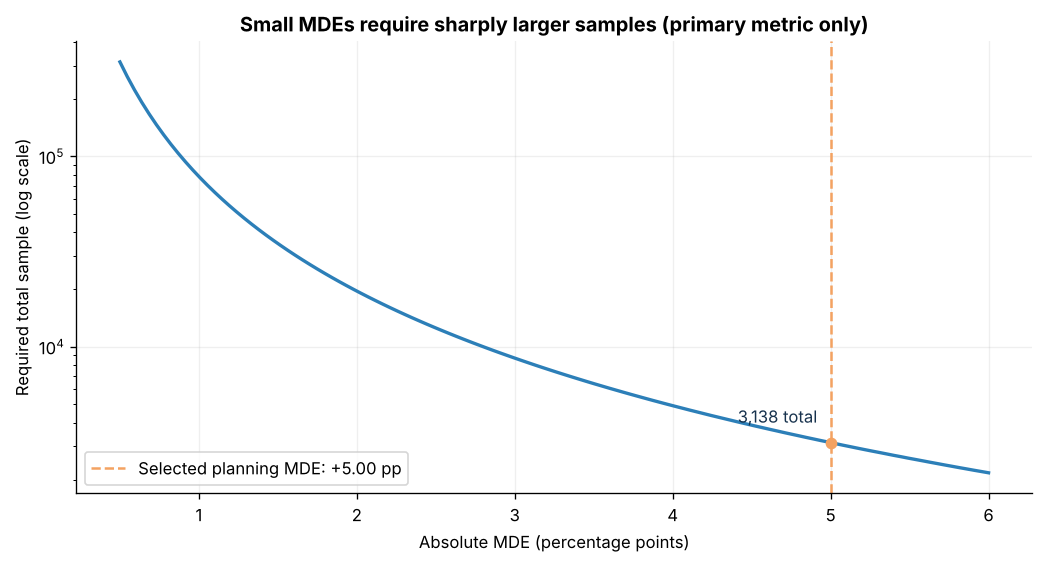

In [3]:
ALPHA = 0.05
TARGET_POWER = 0.80
PLANNED_MDE = 0.05
OPERATIONAL_BUFFER = 0.05

def sample_size_per_arm(
    baseline,
    absolute_mde,
    alpha=ALPHA,
    power=TARGET_POWER,
):
    treatment = baseline + absolute_mde
    if not 0 < baseline < 1 or not 0 < treatment < 1:
        raise ValueError("Baseline and treatment rates must be in (0, 1).")
    z_alpha = NormalDist().inv_cdf(1 - alpha / 2)
    z_power = NormalDist().inv_cdf(power)
    pooled_midpoint = (baseline + treatment) / 2
    numerator = (
        z_alpha
        * sqrt(
            2
            * pooled_midpoint
            * (1 - pooled_midpoint)
        )
        + z_power
        * sqrt(
            baseline * (1 - baseline)
            + treatment * (1 - treatment)
        )
    ) ** 2
    return ceil(numerator / absolute_mde**2)

mde_values = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]
sample_size_rows = []
for mde in mde_values:
    per_arm = sample_size_per_arm(
        historical_baseline_proxy,
        mde,
    )
    total = 2 * per_arm
    expected_days = total / daily_checkout_session_proxy
    sample_size_rows.append(
        {
            "Absolute MDE": mde,
            "Relative lift": mde / historical_baseline_proxy,
            "Per arm": per_arm,
            "Total": total,
            "Proxy weeks": expected_days / 7,
            "Historical-window scenario orders": (
                checkout_sessions * mde
            ),
            "Historical-window scenario revenue": (
                checkout_sessions * mde * average_order_value
            ),
        }
    )

sample_size_grid = pd.DataFrame(sample_size_rows)
sample_size_display = sample_size_grid.copy()
sample_size_display["Absolute MDE"] = sample_size_display[
    "Absolute MDE"
].map(lambda value: f"{value * 100:.2f} pp")
sample_size_display["Relative lift"] = sample_size_display[
    "Relative lift"
].map(lambda value: f"{value:.1%}")
for column in ["Per arm", "Total"]:
    sample_size_display[column] = sample_size_display[column].map(
        lambda value: f"{int(value):,}"
    )
sample_size_display["Proxy weeks"] = sample_size_display[
    "Proxy weeks"
].map(lambda value: f"{value:,.1f}")
sample_size_display["Historical-window scenario orders"] = (
    sample_size_display[
        "Historical-window scenario orders"
    ].map(lambda value: f"{value:,.1f}")
)
sample_size_display["Historical-window scenario revenue"] = (
    sample_size_display[
        "Historical-window scenario revenue"
    ].map(lambda value: f"${value:,.0f}")
)
display(sample_size_display)

core_n_per_arm = sample_size_per_arm(
    historical_baseline_proxy,
    PLANNED_MDE,
)
primary_only_per_arm = ceil(
    core_n_per_arm * (1 + OPERATIONAL_BUFFER)
)
primary_only_total = 2 * primary_only_per_arm
primary_only_weeks = (
    primary_only_total / daily_checkout_session_proxy / 7
)

assert core_n_per_arm == 1_569
assert primary_only_per_arm == 1_648
assert primary_only_total == 3_296

curve_mde = np.linspace(0.005, 0.06, 120)
curve_total = np.array(
    [
        2
        * sample_size_per_arm(
            historical_baseline_proxy,
            value,
        )
        for value in curve_mde
    ]
)
fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.plot(curve_mde * 100, curve_total, color=BLUE, linewidth=2)
ax.axvline(
    PLANNED_MDE * 100,
    color=ORANGE,
    linestyle="--",
    label="Selected planning MDE: +5.00 pp",
)
ax.scatter(
    [PLANNED_MDE * 100],
    [2 * core_n_per_arm],
    color=ORANGE,
    zorder=3,
)
ax.annotate(
    f"{2 * core_n_per_arm:,} total",
    (PLANNED_MDE * 100, 2 * core_n_per_arm),
    xytext=(-8, 12),
    textcoords="offset points",
    ha="right",
    color=NAVY,
)
ax.set_yscale("log")
ax.set_xlabel("Absolute MDE (percentage points)")
ax.set_ylabel("Required total sample (log scale)")
ax.set_title(
    "Small MDEs require sharply larger samples (primary metric only)"
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "06_sample_size_curve.png",
    bbox_inches="tight",
)
plt.show()

In [4]:
baseline_sensitivity = pd.DataFrame(
    [
        {
            "Baseline assumption": "Wilson lower bound",
            "Baseline rate": baseline_lower,
            "Per-arm N at +5 pp": sample_size_per_arm(
                baseline_lower,
                PLANNED_MDE,
            ),
        },
        {
            "Baseline assumption": "Historical point estimate",
            "Baseline rate": historical_baseline_proxy,
            "Per-arm N at +5 pp": core_n_per_arm,
        },
        {
            "Baseline assumption": "Wilson upper bound",
            "Baseline rate": baseline_upper,
            "Per-arm N at +5 pp": sample_size_per_arm(
                baseline_upper,
                PLANNED_MDE,
            ),
        },
    ]
)
baseline_sensitivity_display = baseline_sensitivity.copy()
baseline_sensitivity_display["Baseline rate"] = (
    baseline_sensitivity_display["Baseline rate"].map(
        lambda value: f"{value:.2%}"
    )
)
baseline_sensitivity_display["Per-arm N at +5 pp"] = (
    baseline_sensitivity_display["Per-arm N at +5 pp"].map(
        lambda value: f"{int(value):,}"
    )
)
display(baseline_sensitivity_display)

print(
    f"Primary-metric sample: {core_n_per_arm:,} per arm "
    f"({2 * core_n_per_arm:,} total)."
)
print(
    f"With a 5% operational buffer: {primary_only_per_arm:,} per arm "
    f"({primary_only_total:,} total), about "
    f"{primary_only_weeks:.2f} proxy weeks."
)
print(
    "This was the original enrollment plan. Section 6 tests whether "
    "it can ship a change that meets the MDE."
)

,Baseline assumption,Baseline rate,Per-arm N at +5 pp
0,Wilson lower bound,46.67%,"1,569"
1,Historical point estimate,48.02%,"1,569"
2,Wilson upper bound,49.38%,"1,567"


Primary-metric sample: 1,569 per arm (3,138 total).
With a 5% operational buffer: 1,648 per arm (3,296 total), about 8.35 proxy weeks.
This was the original enrollment plan. Section 6 tests whether it can ship a change that meets the MDE.


The earlier +0.50 pp opportunity scenario is not a feasible MDE at the
observed traffic proxy: it would require approximately 313,580 eligible
users in total, or about 795 proxy weeks. Opportunity sizing and
experiment detectability answer different questions.

## 5. Fixed-duration MDE

The next table reverses the calculation: if the test is limited to a
fixed number of weeks, what absolute lift is detectable? The throughput
uses historical **checkout sessions**, not deduplicated eligible users,
so it is optimistic until a shadow assignment validates current
user-level traffic.

,Weeks,Proxy total eligible units,Proxy units per arm,Fixed-N MDE
0,4,"1,578",789,7.04 pp
1,6,"2,367","1,183",5.76 pp
2,8,"3,157","1,578",4.98 pp
3,12,"4,735","2,367",4.07 pp
4,16,"6,314","3,157",3.53 pp
5,24,"9,471","4,735",2.88 pp


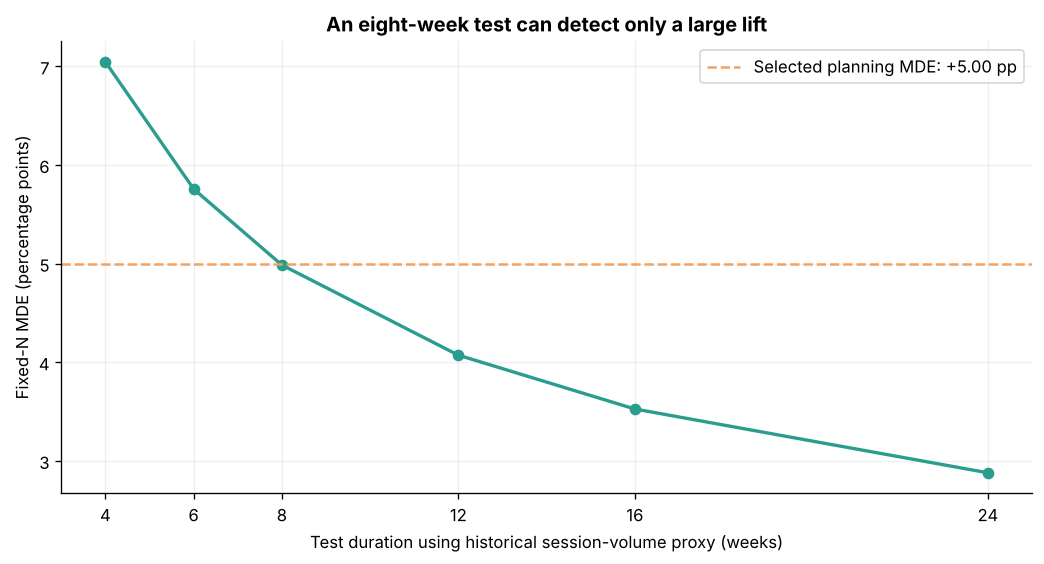

In [5]:
def fixed_n_mde(baseline, n_per_arm):
    lower = 1e-6
    upper = min(0.25, 1 - baseline - 1e-6)
    for _ in range(80):
        midpoint = (lower + upper) / 2
        if sample_size_per_arm(baseline, midpoint) <= n_per_arm:
            upper = midpoint
        else:
            lower = midpoint
    return upper

duration_weeks = [4, 6, 8, 12, 16, 24]
duration_rows = []
for weeks in duration_weeks:
    proxy_total = floor(
        daily_checkout_session_proxy * 7 * weeks
    )
    proxy_per_arm = floor(proxy_total / 2)
    duration_rows.append(
        {
            "Weeks": weeks,
            "Proxy total eligible units": proxy_total,
            "Proxy units per arm": proxy_per_arm,
            "Fixed-N MDE": fixed_n_mde(
                historical_baseline_proxy,
                proxy_per_arm,
            ),
        }
    )
duration_sensitivity = pd.DataFrame(duration_rows)
duration_display = duration_sensitivity.copy()
for column in [
    "Proxy total eligible units",
    "Proxy units per arm",
]:
    duration_display[column] = duration_display[column].map(
        lambda value: f"{int(value):,}"
    )
duration_display["Fixed-N MDE"] = duration_display[
    "Fixed-N MDE"
].map(lambda value: f"{value * 100:.2f} pp")
display(duration_display)

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.plot(
    duration_sensitivity["Weeks"],
    duration_sensitivity["Fixed-N MDE"] * 100,
    marker="o",
    color=TEAL,
    linewidth=2,
)
ax.axhline(
    PLANNED_MDE * 100,
    color=ORANGE,
    linestyle="--",
    label="Selected planning MDE: +5.00 pp",
)
ax.set_xticks(duration_weeks)
ax.set_xlabel("Test duration using historical session-volume proxy (weeks)")
ax.set_ylabel("Fixed-N MDE (percentage points)")
ax.set_title("An eight-week test can detect only a large lift")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "07_duration_mde.png",
    bbox_inches="tight",
)
plt.show()

## 6. Decision-rule audit: can the original plan ship a real winner?

The original plan enrolled 1,648 users per arm (3,296 in total, about
8.4 proxy weeks) and shipped only if three conditions held:

1. the primary 95% interval was above zero;
2. the point estimate was at least the +5.00 pp MDE; and
3. the payment-error upper bound stayed below the +1.50 pp margin.

The sample size was calculated for the first condition alone. The
simulation below applies the **whole rule** at the planned 1,569-user
statistical core, when the true lift equals the MDE and payment errors
do not change. The payment-error base rate is an assumption (4%) until
real telemetry exists.

In [6]:
DECISION_SEED = 20_260_801
DECISION_REPETITIONS = 40_000
PAYMENT_ERROR_BASE_RATE = 0.04
PAYMENT_ERROR_MARGIN = 0.015
AUDIT_LIFTS = np.round(np.arange(0, 0.0801, 0.01), 4)


def wilson_bounds(successes, trials, z=Z_95):
    successes = np.asarray(successes, dtype=float)
    trials = np.asarray(trials, dtype=float)
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    center = (proportion + z**2 / (2 * trials)) / denominator
    half_width = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / trials
            + z**2 / (4 * trials**2)
        )
        / denominator
    )
    return center - half_width, center + half_width


def newcombe_bounds(x1, n1, x2, n2, z=Z_95):
    # First-minus-second difference with Newcombe hybrid score bounds.
    p1 = np.asarray(x1, dtype=float) / np.asarray(n1, dtype=float)
    p2 = np.asarray(x2, dtype=float) / np.asarray(n2, dtype=float)
    lower1, upper1 = wilson_bounds(x1, n1, z)
    lower2, upper2 = wilson_bounds(x2, n2, z)
    difference = p1 - p2
    lower = difference - np.sqrt(
        (p1 - lower1) ** 2 + (upper2 - p2) ** 2
    )
    upper = difference + np.sqrt(
        (upper1 - p1) ** 2 + (p2 - lower2) ** 2
    )
    return difference, lower, upper


def pooled_z(x1, n1, x2, n2):
    x1, n1, x2, n2 = (
        np.asarray(value, dtype=float) for value in (x1, n1, x2, n2)
    )
    pooled = (x1 + x2) / (n1 + n2)
    standard_error = np.sqrt(
        pooled * (1 - pooled) * (1 / n1 + 1 / n2)
    )
    return (x1 / n1 - x2 / n2) / standard_error


def simulate_fixed_rule(
    n_per_arm,
    true_lift,
    payment_harm,
    require_point_estimate,
    margin=PAYMENT_ERROR_MARGIN,
):
    # Every call reuses the decision seed (common random numbers), so
    # scenarios differ only by their assumptions.
    rng = np.random.default_rng(DECISION_SEED)
    draws = DECISION_REPETITIONS
    control = rng.binomial(n_per_arm, historical_baseline_proxy, draws)
    treatment = rng.binomial(
        n_per_arm, historical_baseline_proxy + true_lift, draws
    )
    control_errors = rng.binomial(
        n_per_arm, PAYMENT_ERROR_BASE_RATE, draws
    )
    treatment_errors = rng.binomial(
        n_per_arm, PAYMENT_ERROR_BASE_RATE + payment_harm, draws
    )
    effect, effect_lower, _ = newcombe_bounds(
        treatment, n_per_arm, control, n_per_arm
    )
    _, _, error_upper = newcombe_bounds(
        treatment_errors, n_per_arm, control_errors, n_per_arm
    )
    primary_pass = effect_lower > 0
    point_pass = effect >= PLANNED_MDE
    guardrail_pass = error_upper < margin
    ship = primary_pass & guardrail_pass
    if require_point_estimate:
        ship = ship & point_pass
    return {
        "primary_interval": float(primary_pass.mean()),
        "point_estimate": float(point_pass.mean()),
        "guardrail": float(guardrail_pass.mean()),
        "ship": float(ship.mean()),
    }


original_at_mde = simulate_fixed_rule(
    core_n_per_arm, PLANNED_MDE, 0.0, True
)
original_no_effect = simulate_fixed_rule(core_n_per_arm, 0.0, 0.0, True)
corrected_at_original_n = simulate_fixed_rule(
    core_n_per_arm, PLANNED_MDE, 0.0, False
)
original_curve = [
    simulate_fixed_rule(core_n_per_arm, lift, 0.0, True)["ship"]
    for lift in AUDIT_LIFTS
]

audit_table = pd.DataFrame(
    [
        {
            "Condition at a true +5.00 pp lift": (
                "1. Primary 95% interval above zero"
            ),
            "Probability": original_at_mde["primary_interval"],
        },
        {
            "Condition at a true +5.00 pp lift": (
                "2. Point estimate at least +5.00 pp"
            ),
            "Probability": original_at_mde["point_estimate"],
        },
        {
            "Condition at a true +5.00 pp lift": (
                "3. Payment-error upper bound below "
                f"+{PAYMENT_ERROR_MARGIN * 100:.2f} pp"
            ),
            "Probability": original_at_mde["guardrail"],
        },
        {
            "Condition at a true +5.00 pp lift": (
                "All three: the original ship rule"
            ),
            "Probability": original_at_mde["ship"],
        },
        {
            "Condition at a true +5.00 pp lift": (
                "Conditions 1 and 3 only (no point-estimate hurdle)"
            ),
            "Probability": corrected_at_original_n["ship"],
        },
    ]
)
audit_display = audit_table.copy()
audit_display["Probability"] = audit_display["Probability"].map(
    lambda value: f"{value:.1%}"
)
display(audit_display)
print(
    f"At {core_n_per_arm:,} users per arm the original rule ships a "
    f"true +5.00 pp lift {original_at_mde['ship']:.1%} of the time "
    f"and a no-effect change {original_no_effect['ship']:.2%} of "
    "the time."
)

,Condition at a true +5.00 pp lift,Probability
0,1. Primary 95% interval above zero,80.5%
1,2. Point estimate at least +5.00 pp,50.1%
2,3. Payment-error upper bound below +1.50 pp,56.7%
3,All three: the original ship rule,28.6%
4,Conditions 1 and 3 only (no point-estimate hurdle),45.9%


At 1,569 users per arm the original rule ships a true +5.00 pp lift 28.6% of the time and a no-effect change 0.16% of the time.


The plan was powered for condition 1 only. Requiring the point estimate
to reach the MDE cuts the chance of shipping a true +5.00 pp lift to
about one half by construction: an unbiased estimate lands below its
true value about half the time. The payment-error check, which the
sample size never accounted for, removes a further share. Two
corrections follow:

- **Ship on evidence, not on the point estimate.** The MDE sets the
  sample size; it is not a second hurdle for the estimate. A change
  ships when its interval excludes zero and its guardrails pass.
- **Size the test for the guardrail as well as the primary metric.**

## 7. Size the test for the guardrail too

The payment-error guardrail is a non-inferiority test: it passes only
when the upper bound of the treatment-minus-control difference is below
the margin. Its power depends on the margin and on the payment-error
base rate. A change ships only if both tests pass, so the sample must
make the **joint** probability at least 80% when the true lift equals
the MDE and payment errors do not change. The closed-form calculation
below multiplies the two normal-approximation powers, which treats the
two outcomes as independent.

In [7]:
def fixed_design_power(
    n_per_arm,
    margin,
    lift=PLANNED_MDE,
    base_rate=PAYMENT_ERROR_BASE_RATE,
):
    treatment_rate = historical_baseline_proxy + lift
    primary_standard_error = sqrt(
        (
            historical_baseline_proxy * (1 - historical_baseline_proxy)
            + treatment_rate * (1 - treatment_rate)
        )
        / n_per_arm
    )
    guardrail_standard_error = sqrt(
        2 * base_rate * (1 - base_rate) / n_per_arm
    )
    primary = NormalDist().cdf(lift / primary_standard_error - Z_95)
    guardrail = NormalDist().cdf(
        margin / guardrail_standard_error - Z_95
    )
    return primary, guardrail


def fixed_design_n(
    margin,
    base_rate=PAYMENT_ERROR_BASE_RATE,
    power=TARGET_POWER,
):
    # Smallest per-arm sample, in steps of 10, whose joint power
    # reaches the target.
    n_per_arm = 10
    while True:
        primary, guardrail = fixed_design_power(
            n_per_arm, margin, base_rate=base_rate
        )
        if primary * guardrail >= power:
            return n_per_arm
        n_per_arm += 10


MARGIN_OPTIONS = [0.010, 0.015, 0.020, 0.025, 0.030]
guardrail_rows = []
for margin in MARGIN_OPTIONS:
    _, guardrail_power = fixed_design_power(core_n_per_arm, margin)
    fixed_n = fixed_design_n(margin)
    enrollment_total = 2 * ceil(fixed_n * (1 + OPERATIONAL_BUFFER))
    guardrail_rows.append(
        {
            "Payment-error margin": f"+{margin * 100:.1f} pp",
            f"Guardrail power at {core_n_per_arm:,}/arm": (
                f"{guardrail_power:.0%}"
            ),
            "Fixed-design users per arm": f"{fixed_n:,}",
            "Enrollment total (5% buffer)": f"{enrollment_total:,}",
            "Proxy weeks": (
                f"{enrollment_total / daily_checkout_session_proxy / 7:.1f}"
            ),
        }
    )
display(pd.DataFrame(guardrail_rows))

display(
    pd.DataFrame(
        [
            {
                "Assumed payment-error rate": f"{base_rate:.0%}",
                "Fixed-design users per arm at +1.5 pp": (
                    f"{fixed_design_n(PAYMENT_ERROR_MARGIN, base_rate=base_rate):,}"
                ),
            }
            for base_rate in [0.02, 0.04, 0.06]
        ]
    )
)

fixed_core_per_arm = fixed_design_n(PAYMENT_ERROR_MARGIN)
fixed_check = simulate_fixed_rule(
    fixed_core_per_arm, PLANNED_MDE, 0.0, False
)
assert fixed_core_per_arm == 2_880
print(
    f"At the provisional +{PAYMENT_ERROR_MARGIN * 100:.1f} pp margin a "
    f"fixed-sample test needs {fixed_core_per_arm:,} users per arm. "
    "Simulated probability that the corrected rule ships a true "
    f"+5.00 pp lift: {fixed_check['ship']:.1%}. The closed form is "
    "slightly optimistic, so section 8 sizes the final plan by "
    "simulating the full decision procedure."
)

,Payment-error margin,"Guardrail power at 1,569/arm",Fixed-design users per arm,Enrollment total (5% buffer),Proxy weeks
0,+1.0 pp,30%,"6,040","12,684",32.1
1,+1.5 pp,57%,"2,880","6,048",15.3
2,+2.0 pp,82%,"2,020","4,242",10.7
3,+2.5 pp,95%,"1,710","3,592",9.1
4,+3.0 pp,99%,"1,600","3,360",8.5


,Assumed payment-error rate,Fixed-design users per arm at +1.5 pp
0,2%,"1,930"
1,4%,"2,880"
2,6%,"3,990"


At the provisional +1.5 pp margin a fixed-sample test needs 2,880 users per arm. Simulated probability that the corrected rule ships a true +5.00 pp lift: 79.5%. The closed form is slightly optimistic, so section 8 sizes the final plan by simulating the full decision procedure.


## 8. Peeking and the sequential plan

Few teams wait three months without looking. Reading the result
repeatedly with an unadjusted 5% test inflates false positives,
because every look is another chance for noise to cross the line.

An O'Brien-Fleming design spends the 5% error budget across a small
number of planned looks: early boundaries are very strict and the
final one is close to the usual 1.96. Every decision at a look uses the
same boundary, both for the primary z-statistic and for the confidence
level of the payment-error interval:

- **Ship early** if the primary z-statistic reaches the boundary and
  the payment-error upper bound is below the margin.
- **Stop for harm** if the payment-error lower bound is above zero.
- **Stop for futility** at the halfway look if the observed lift is
  zero or negative. The rule is non-binding, so ignoring it cannot
  raise the false-positive rate.
- At the final look, ship only on the same efficacy and guardrail
  criteria.

The maximum sample starts from the closed-form fixed design times the
O'Brien-Fleming inflation factor and is then raised in steps of 10
until the simulated full procedure ships a true +5.00 pp lift at least
80% of the time.

In [8]:
PLANNED_LOOKS = 4


def look_correlation(looks):
    fractions = np.arange(1, looks + 1) / looks
    correlation = np.minimum.outer(fractions, fractions) / np.sqrt(
        np.outer(fractions, fractions)
    )
    return fractions, correlation


def crossing_rate(bounds, repetitions=100_000, chunk=20_000):
    # Share of no-effect z-statistic paths, read at equally spaced
    # looks, that cross a two-sided boundary at least once.
    bounds = np.asarray(bounds, dtype=float)
    looks = len(bounds)
    rng = np.random.default_rng(DECISION_SEED)
    scale = np.sqrt(np.arange(1, looks + 1))
    crossed = 0
    for start in range(0, repetitions, chunk):
        size = min(chunk, repetitions - start)
        paths = rng.standard_normal((size, looks)).cumsum(axis=1) / scale
        crossed += int((np.abs(paths) >= bounds).any(axis=1).sum())
    return crossed / repetitions


def unadjusted_false_positive_rate(looks):
    return crossing_rate(np.full(looks, Z_95))


def obf_boundaries(looks, alpha=ALPHA):
    if looks == 1:
        return np.array([NormalDist().inv_cdf(1 - alpha / 2)])
    fractions, correlation = look_correlation(looks)
    distribution = multivariate_normal(
        mean=np.zeros(looks), cov=correlation, seed=DECISION_SEED
    )

    def excess(constant):
        bounds = constant / np.sqrt(fractions)
        return 1 - distribution.cdf(bounds, lower_limit=-bounds) - alpha

    return brentq(excess, 1.5, 4.0, xtol=1e-7) / np.sqrt(fractions)


def inflation_factor(looks, power, alpha=ALPHA):
    # Maximum-sample multiplier that keeps power for the primary
    # metric under O'Brien-Fleming boundaries.
    if looks == 1:
        return 1.0
    fractions, correlation = look_correlation(looks)
    bounds = obf_boundaries(looks, alpha)

    def shortfall(drift):
        distribution = multivariate_normal(
            mean=drift * np.sqrt(fractions),
            cov=correlation,
            seed=DECISION_SEED,
        )
        return 1 - distribution.cdf(bounds) - power

    drift = brentq(shortfall, 0.5, 8.0, xtol=1e-7)
    z_sum = NormalDist().inv_cdf(1 - alpha / 2) + NormalDist().inv_cdf(
        power
    )
    return (drift / z_sum) ** 2


plan_bounds = obf_boundaries(PLANNED_LOOKS)
assert np.allclose(plan_bounds, [4.049, 2.863, 2.337, 2.024], atol=0.002)
obf_false_positive_rate = crossing_rate(plan_bounds)

PLANNER_LOOKS = [1, 2, 3, 4, 5, 6]
PLANNER_POWERS = [0.70, 0.80, 0.90]
inflation_table = {
    looks: {power: inflation_factor(looks, power) for power in PLANNER_POWERS}
    for looks in PLANNER_LOOKS
}
display(
    pd.DataFrame(
        [
            {
                "Planned looks": looks,
                "Inflation at 70% power": f"{factors[0.70]:.4f}",
                "Inflation at 80% power": f"{factors[0.80]:.4f}",
                "Inflation at 90% power": f"{factors[0.90]:.4f}",
            }
            for looks, factors in inflation_table.items()
        ]
    )
)

,Planned looks,Inflation at 70% power,Inflation at 80% power,Inflation at 90% power
0,1,1.0000,1.0000,1.0000
1,2,1.0083,1.0078,1.0071
2,3,1.0185,1.0174,1.0161
3,4,1.0252,1.0238,1.0222
4,5,1.0300,1.0284,1.0265
5,6,1.0335,1.0318,1.0297


In [9]:
def simulate_sequential(
    n_per_arm,
    true_lift,
    payment_harm,
    margin=PAYMENT_ERROR_MARGIN,
    bounds=None,
    repetitions=DECISION_REPETITIONS,
):
    bounds = plan_bounds if bounds is None else np.asarray(bounds)
    rng = np.random.default_rng(DECISION_SEED)
    looks = len(bounds)
    look_sizes = np.round(
        n_per_arm * np.arange(1, looks + 1) / looks
    ).astype(int)
    increments = np.diff(np.concatenate([[0], look_sizes]))

    def cumulative(rate):
        return rng.binomial(
            increments, rate, (repetitions, looks)
        ).cumsum(axis=1)

    control = cumulative(historical_baseline_proxy)
    treatment = cumulative(historical_baseline_proxy + true_lift)
    control_errors = cumulative(PAYMENT_ERROR_BASE_RATE)
    treatment_errors = cumulative(PAYMENT_ERROR_BASE_RATE + payment_harm)

    active = np.ones(repetitions, dtype=bool)
    shipped = np.zeros(repetitions, dtype=bool)
    harm_stops = np.zeros(repetitions, dtype=bool)
    futility_stops = np.zeros(repetitions, dtype=bool)
    guardrail_blocks = np.zeros(repetitions, dtype=bool)
    stop_fraction = np.ones(repetitions)
    for look in range(looks):
        n = look_sizes[look]
        z = pooled_z(treatment[:, look], n, control[:, look], n)
        _, error_lower, error_upper = newcombe_bounds(
            treatment_errors[:, look],
            n,
            control_errors[:, look],
            n,
            z=bounds[look],
        )
        harm = active & (error_lower > 0)
        efficacy = (
            active & ~harm & (z >= bounds[look]) & (error_upper < margin)
        )
        futility = (
            active
            & ~harm
            & ~efficacy
            & (look == looks // 2 - 1)
            & (z <= 0)
        )
        final = active & (look == looks - 1)
        stopping = harm | efficacy | futility | final
        shipped |= efficacy
        harm_stops |= harm
        futility_stops |= futility
        guardrail_blocks |= (
            final & ~harm & ~efficacy & (z >= bounds[look])
        )
        stop_fraction = np.where(
            stopping, (look + 1) / looks, stop_fraction
        )
        active &= ~stopping
    return {
        "ship": float(shipped.mean()),
        "expected_fraction": float(stop_fraction.mean()),
        "harm_stop": float(harm_stops.mean()),
        "futility_stop": float(futility_stops.mean()),
        "guardrail_block": float(guardrail_blocks.mean()),
        "no_significant_lift": float(
            1
            - shipped.mean()
            - harm_stops.mean()
            - futility_stops.mean()
            - guardrail_blocks.mean()
        ),
    }


def sequential_core_n(margin, power=TARGET_POWER):
    n_per_arm = (
        ceil(
            fixed_design_n(margin)
            * inflation_table[PLANNED_LOOKS][power]
            / 10
        )
        * 10
    )
    while (
        simulate_sequential(n_per_arm, PLANNED_MDE, 0.0, margin)["ship"]
        < power
    ):
        n_per_arm += 10
    return n_per_arm


plan_core_per_arm = sequential_core_n(PAYMENT_ERROR_MARGIN)
plan_enrollment_per_arm = ceil(
    plan_core_per_arm * (1 + OPERATIONAL_BUFFER)
)
plan_enrollment_total = 2 * plan_enrollment_per_arm
plan_max_weeks = (
    plan_enrollment_total / daily_checkout_session_proxy / 7
)
plan_look_fractions = np.arange(1, PLANNED_LOOKS + 1) / PLANNED_LOOKS

plan_scenarios = {
    "no_effect": simulate_sequential(plan_core_per_arm, 0.0, 0.0),
    "half_mde": simulate_sequential(
        plan_core_per_arm, PLANNED_MDE / 2, 0.0
    ),
    "mde": simulate_sequential(plan_core_per_arm, PLANNED_MDE, 0.0),
    "mde_with_harm": simulate_sequential(
        plan_core_per_arm, PLANNED_MDE, PAYMENT_ERROR_MARGIN
    ),
}
plan_curve = [
    simulate_sequential(plan_core_per_arm, lift, 0.0)
    for lift in AUDIT_LIFTS
]

boundary_table = pd.DataFrame(
    {
        "Look": np.arange(1, PLANNED_LOOKS + 1),
        "Proxy week": [
            f"{plan_max_weeks * fraction:.1f}"
            for fraction in plan_look_fractions
        ],
        "Enrolled per arm": [
            f"{round(plan_enrollment_per_arm * fraction):,}"
            for fraction in plan_look_fractions
        ],
        "z boundary": [f"{bound:.3f}" for bound in plan_bounds],
        "Nominal two-sided p": [
            f"{2 * (1 - NormalDist().cdf(bound)):.5f}"
            for bound in plan_bounds
        ],
    }
)
display(boundary_table)

scenario_labels = {
    "no_effect": "No true effect",
    "half_mde": "True lift +2.50 pp",
    "mde": "True lift +5.00 pp (MDE)",
    "mde_with_harm": (
        "True lift +5.00 pp, payment errors "
        f"+{PAYMENT_ERROR_MARGIN * 100:.2f} pp"
    ),
}
display(
    pd.DataFrame(
        [
            {
                "Scenario": scenario_labels[key],
                "Ships": f"{result['ship']:.1%}",
                "Stops for harm": f"{result['harm_stop']:.1%}",
                "Stops for futility": f"{result['futility_stop']:.1%}",
                "Guardrail blocks at final look": (
                    f"{result['guardrail_block']:.1%}"
                ),
                "No significant lift": (
                    f"{result['no_significant_lift']:.1%}"
                ),
                "Expected proxy weeks": (
                    f"{result['expected_fraction'] * plan_max_weeks:.1f}"
                ),
            }
            for key, result in plan_scenarios.items()
        ]
    )
)

plan_days = plan_enrollment_total / daily_checkout_session_proxy
weekly_looks = int(plan_days // 7)
daily_looks = int(ceil(plan_days))
peeking_looks = sorted({1, 2, 3, 4, 6, 8, 12, weekly_looks, daily_looks})
peeking_rates = {
    looks: unadjusted_false_positive_rate(looks) for looks in peeking_looks
}
display(
    pd.DataFrame(
        [
            {
                "Monitoring": "One read at the end",
                "Looks": 1,
                "False-positive rate": f"{peeking_rates[1]:.1%}",
            },
            {
                "Monitoring": "Weekly reads, unadjusted",
                "Looks": weekly_looks,
                "False-positive rate": (
                    f"{peeking_rates[weekly_looks]:.1%}"
                ),
            },
            {
                "Monitoring": "Daily reads, unadjusted",
                "Looks": daily_looks,
                "False-positive rate": f"{peeking_rates[daily_looks]:.1%}",
            },
            {
                "Monitoring": "Four planned reads, O'Brien-Fleming",
                "Looks": PLANNED_LOOKS,
                "False-positive rate": f"{obf_false_positive_rate:.1%}",
            },
        ]
    )
)
print(
    f"Plan: up to {plan_enrollment_total:,} users "
    f"({plan_enrollment_per_arm:,} per arm, {plan_max_weeks:.1f} proxy "
    "weeks); expected "
    f"{plan_scenarios['mde']['expected_fraction'] * plan_max_weeks:.1f} "
    "weeks if the lift is real and "
    f"{plan_scenarios['no_effect']['expected_fraction'] * plan_max_weeks:.1f} "
    "weeks if there is no effect."
)

,Look,Proxy week,Enrolled per arm,z boundary,Nominal two-sided p
0,1,3.9,777,4.049,0.00005
1,2,7.9,"1,554",2.863,0.00420
2,3,11.8,"2,331",2.337,0.01942
3,4,15.8,"3,108",2.024,0.04294


,Scenario,Ships,Stops for harm,Stops for futility,Guardrail blocks at final look,No significant lift,Expected proxy weeks
0,No true effect,2.0%,1.2%,50.9%,0.3%,45.7%,11.7
1,True lift +2.50 pp,38.6%,2.2%,8.6%,7.0%,43.6%,14.4
2,True lift +5.00 pp (MDE),80.1%,2.5%,0.3%,14.2%,3.0%,13.4
3,"True lift +5.00 pp, payment errors +1.50 pp",2.4%,76.4%,0.3%,20.2%,0.7%,13.1


,Monitoring,Looks,False-positive rate
0,One read at the end,1,5.0%
1,"Weekly reads, unadjusted",15,22.5%
2,"Daily reads, unadjusted",111,38.4%
3,"Four planned reads, O'Brien-Fleming",4,5.0%


Plan: up to 6,216 users (3,108 per arm, 15.8 proxy weeks); expected 13.4 weeks if the lift is real and 11.7 weeks if there is no effect.


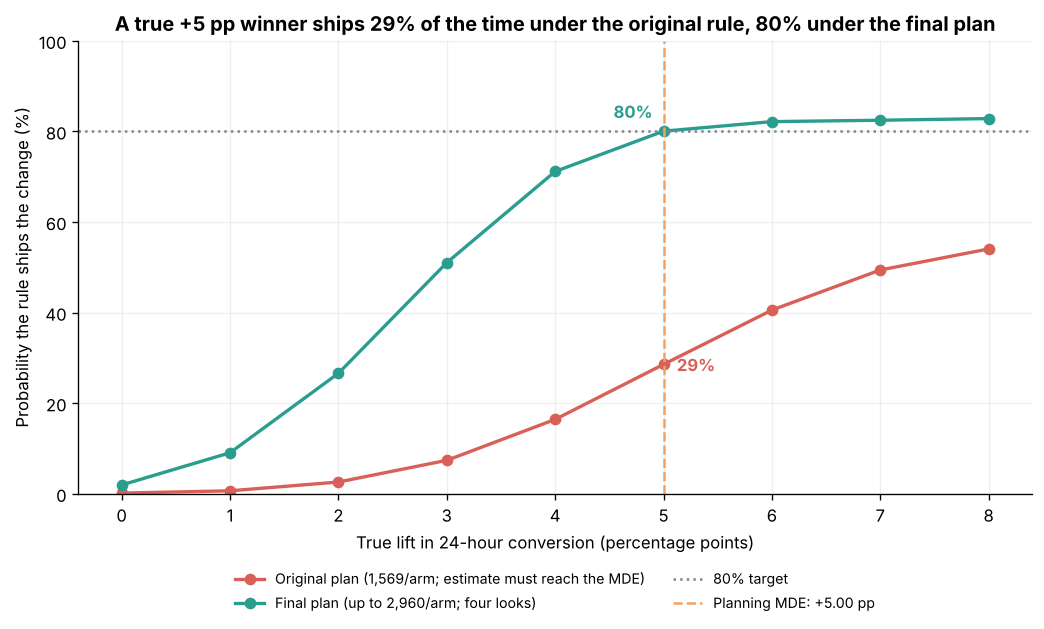

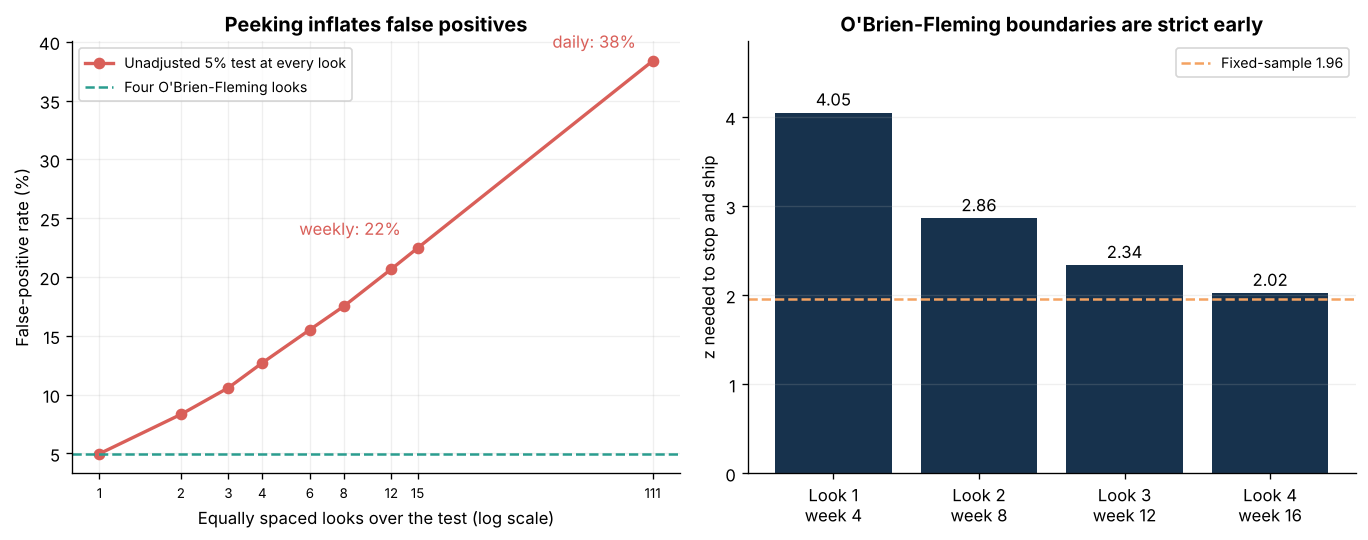

In [10]:
fig, ax = plt.subplots(figsize=(8.8, 5.4))
lifts_pp = AUDIT_LIFTS * 100
ax.plot(
    lifts_pp,
    np.array(original_curve) * 100,
    marker="o",
    color=RED,
    linewidth=2,
    label=(
        f"Original plan ({core_n_per_arm:,}/arm; estimate must "
        "reach the MDE)"
    ),
)
ax.plot(
    lifts_pp,
    np.array([result["ship"] for result in plan_curve]) * 100,
    marker="o",
    color=TEAL,
    linewidth=2,
    label=(
        f"Final plan (up to {plan_core_per_arm:,}/arm; four looks)"
    ),
)
ax.axhline(
    TARGET_POWER * 100, color=GREY, linestyle=":", label="80% target"
)
ax.axvline(
    PLANNED_MDE * 100,
    color=ORANGE,
    linestyle="--",
    label="Planning MDE: +5.00 pp",
)
for value, color, offset in [
    (original_at_mde["ship"], RED, (8, -4)),
    (plan_scenarios["mde"]["ship"], TEAL, (-30, 8)),
]:
    ax.annotate(
        f"{value:.0%}",
        (PLANNED_MDE * 100, value * 100),
        xytext=offset,
        textcoords="offset points",
        color=color,
        fontweight="bold",
    )
ax.set_xlabel("True lift in 24-hour conversion (percentage points)")
ax.set_ylabel("Probability the rule ships the change (%)")
ax.set_title(
    "A true +5 pp winner ships "
    f"{original_at_mde['ship']:.0%} of the time under the original rule, "
    f"{plan_scenarios['mde']['ship']:.0%} under the final plan"
)
ax.set_ylim(0, 100)
ax.grid(alpha=0.2)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    fontsize=8.5,
    frameon=False,
)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "09_decision_rule_audit.png",
    bbox_inches="tight",
)
plt.show()

fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.6))
left.plot(
    peeking_looks,
    [peeking_rates[looks] * 100 for looks in peeking_looks],
    marker="o",
    color=RED,
    linewidth=2,
    label="Unadjusted 5% test at every look",
)
left.axhline(
    obf_false_positive_rate * 100,
    color=TEAL,
    linestyle="--",
    label="Four O'Brien-Fleming looks",
)
for looks, label in [(weekly_looks, "weekly"), (daily_looks, "daily")]:
    left.annotate(
        f"{label}: {peeking_rates[looks]:.0%}",
        (looks, peeking_rates[looks] * 100),
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        color=RED,
    )
left.set_xscale("log")
left.set_xticks(peeking_looks)
left.set_xticklabels([str(looks) for looks in peeking_looks], fontsize=8)
left.minorticks_off()
left.set_xlabel("Equally spaced looks over the test (log scale)")
left.set_ylabel("False-positive rate (%)")
left.set_title("Peeking inflates false positives")
left.grid(alpha=0.2)
left.legend(fontsize=8.5)

look_labels = [
    f"Look {index}\nweek {plan_max_weeks * fraction:.0f}"
    for index, fraction in enumerate(plan_look_fractions, start=1)
]
bars = right.bar(look_labels, plan_bounds, color=NAVY)
right.axhline(
    Z_95, color=ORANGE, linestyle="--", label="Fixed-sample 1.96"
)
for bar, bound in zip(bars, plan_bounds):
    right.text(
        bar.get_x() + bar.get_width() / 2,
        bound + 0.08,
        f"{bound:.2f}",
        ha="center",
    )
right.set_ylabel("z needed to stop and ship")
right.set_title("O'Brien-Fleming boundaries are strict early")
right.set_ylim(0, max(plan_bounds) + 0.8)
right.grid(axis="y", alpha=0.2)
right.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "10_sequential_monitoring.png",
    bbox_inches="tight",
)
plt.show()

## 9. The guardrail margin is a stakeholder decision

The margin, not the primary metric, now sets the duration. It also caps
the decision: above the MDE the final plan's ship probability flattens
near 83%, because a larger lift does not narrow the payment-error
interval. A tighter margin protects users from more payment-error harm
but needs more traffic. Payments and engineering own that trade-off;
the plan of record keeps the provisional +1.50 pp margin.

In [11]:
tradeoff_rows = []
for margin in MARGIN_OPTIONS:
    core = sequential_core_n(margin)
    enrollment_total = 2 * ceil(core * (1 + OPERATIONAL_BUFFER))
    max_weeks = enrollment_total / daily_checkout_session_proxy / 7
    effective = simulate_sequential(core, PLANNED_MDE, 0.0, margin)
    _, guardrail_power = fixed_design_power(core_n_per_arm, margin)
    tradeoff_rows.append(
        {
            "margin": margin,
            "guardrail_power_original_n": guardrail_power,
            "fixed_core_per_arm": fixed_design_n(margin),
            "sequential_core_per_arm": core,
            "enrollment_total": enrollment_total,
            "max_weeks": max_weeks,
            "expected_weeks_if_effective": (
                effective["expected_fraction"] * max_weeks
            ),
        }
    )
margin_tradeoff = pd.DataFrame(tradeoff_rows)
assert (
    margin_tradeoff.loc[
        np.isclose(margin_tradeoff["margin"], PAYMENT_ERROR_MARGIN),
        "sequential_core_per_arm",
    ].iloc[0]
    == plan_core_per_arm
)

display(
    pd.DataFrame(
        {
            "Payment-error margin": margin_tradeoff["margin"].map(
                lambda value: f"+{value * 100:.1f} pp"
            ),
            "Max users": margin_tradeoff["enrollment_total"].map(
                lambda value: f"{int(value):,}"
            ),
            "Max proxy weeks": margin_tradeoff["max_weeks"].map(
                lambda value: f"{value:.1f}"
            ),
            "Expected weeks if the lift is real": margin_tradeoff[
                "expected_weeks_if_effective"
            ].map(lambda value: f"{value:.1f}"),
        }
    )
)

,Payment-error margin,Max users,Max proxy weeks,Expected weeks if the lift is real
0,+1.0 pp,"13,104",33.2,27.2
1,+1.5 pp,"6,216",15.8,13.4
2,+2.0 pp,"4,410",11.2,9.5
3,+2.5 pp,"3,760",9.5,8.0
4,+3.0 pp,"3,612",9.2,7.5


## 10. Generate one seeded synthetic experiment

> **Everything below is simulated.**

The data-generating process assumes the treatment's true conversion is
exactly 5.00 pp above control and that payment errors do not change.
Units arrive in order and the test is read at the four planned looks.
Revenue and payment-error fields are also synthetic. No synthetic row
is saved as observed GA4 data.

In [12]:
SIMULATION_SEED = 20_260_731
TRUE_SIMULATED_LIFT = PLANNED_MDE

rng = np.random.default_rng(SIMULATION_SEED)
simulated = pd.DataFrame(
    {
        "synthetic_unit_id": [
            f"SIM-{index:06d}"
            for index in range(1, plan_enrollment_total + 1)
        ],
        "variant": rng.choice(
            ["control", "treatment"],
            size=plan_enrollment_total,
            p=[0.5, 0.5],
        ),
    }
)
conversion_probability = np.where(
    simulated["variant"].eq("treatment"),
    historical_baseline_proxy + TRUE_SIMULATED_LIFT,
    historical_baseline_proxy,
)
simulated["converted_within_24h"] = rng.binomial(
    1,
    conversion_probability,
).astype(bool)
simulated_order_value = rng.gamma(
    shape=4,
    scale=average_order_value / 4,
    size=plan_enrollment_total,
)
simulated["purchase_revenue_usd"] = np.where(
    simulated["converted_within_24h"],
    simulated_order_value,
    0.0,
)
simulated["payment_error"] = rng.binomial(
    1,
    PAYMENT_ERROR_BASE_RATE,
    size=plan_enrollment_total,
).astype(bool)
simulated["assignment_probability"] = 0.5
simulated["is_simulated"] = True

assert len(simulated) == plan_enrollment_total
assert simulated["synthetic_unit_id"].is_unique
assert simulated["is_simulated"].all()
assert set(simulated["variant"]) == {"control", "treatment"}
assert (
    simulated.loc[
        ~simulated["converted_within_24h"],
        "purchase_revenue_usd",
    ]
    == 0
).all()

print(
    "SIMULATED DATA ONLY — these rows are not observed GA4 users "
    "or experiment results."
)
display(simulated.head(8))

SIMULATED DATA ONLY — these rows are not observed GA4 users or experiment results.


,synthetic_unit_id,variant,converted_within_24h,purchase_revenue_usd,payment_error,assignment_probability,is_simulated
0,SIM-000001,treatment,True,37.8118,False,0.5000,True
1,SIM-000002,control,True,89.2964,False,0.5000,True
2,SIM-000003,control,False,0.0000,False,0.5000,True
3,SIM-000004,control,False,0.0000,False,0.5000,True
4,SIM-000005,treatment,False,0.0000,False,0.5000,True
5,SIM-000006,treatment,False,0.0000,False,0.5000,True
6,SIM-000007,control,False,0.0000,False,0.5000,True
7,SIM-000008,treatment,True,42.1961,False,0.5000,True


## 11. Read the simulated test at the planned looks

Each look uses every unit enrolled so far. Sample-ratio mismatch is
checked first; a p-value below 0.001 blocks interpretation. The rules
from section 8 are then applied in order: harm, efficacy, futility
(halfway look only), and the final read. Intervals use the look's
boundary as their critical value, so they are repeated confidence
intervals rather than ordinary 95% intervals.

In [13]:
def srm_p_value(control_count, treatment_count):
    expected = (control_count + treatment_count) / 2
    chi_square = (
        (control_count - expected) ** 2
        + (treatment_count - expected) ** 2
    ) / expected
    return erfc(sqrt(chi_square / 2))


look_results = []
for look in range(1, PLANNED_LOOKS + 1):
    enrolled = round(plan_enrollment_total * look / PLANNED_LOOKS)
    window = simulated.iloc[:enrolled]
    arms = (
        window.groupby("variant")
        .agg(
            assigned_users=("synthetic_unit_id", "count"),
            converted_users=("converted_within_24h", "sum"),
            payment_errors=("payment_error", "sum"),
        )
        .reindex(["control", "treatment"])
    )
    control_arm = arms.loc["control"]
    treatment_arm = arms.loc["treatment"]
    bound = float(plan_bounds[look - 1])
    look_srm = srm_p_value(
        int(control_arm["assigned_users"]),
        int(treatment_arm["assigned_users"]),
    )
    z_value = float(
        pooled_z(
            treatment_arm["converted_users"],
            treatment_arm["assigned_users"],
            control_arm["converted_users"],
            control_arm["assigned_users"],
        )
    )
    effect, effect_lower, effect_upper = (
        float(value)
        for value in newcombe_bounds(
            treatment_arm["converted_users"],
            treatment_arm["assigned_users"],
            control_arm["converted_users"],
            control_arm["assigned_users"],
            z=bound,
        )
    )
    error_effect, error_lower, error_upper = (
        float(value)
        for value in newcombe_bounds(
            treatment_arm["payment_errors"],
            treatment_arm["assigned_users"],
            control_arm["payment_errors"],
            control_arm["assigned_users"],
            z=bound,
        )
    )
    if look_srm < 0.001:
        look_decision = "Stop: sample-ratio mismatch"
    elif error_lower > 0:
        look_decision = "Stop for harm"
    elif z_value >= bound and error_upper < PAYMENT_ERROR_MARGIN:
        look_decision = "Ship"
    elif look == PLANNED_LOOKS // 2 and z_value <= 0:
        look_decision = "Stop for futility"
    elif look == PLANNED_LOOKS and z_value >= bound:
        look_decision = "Do not ship: guardrail not cleared"
    elif look == PLANNED_LOOKS:
        look_decision = "Do not ship: lift not significant"
    else:
        look_decision = "Continue"
    look_results.append(
        {
            "look": look,
            "enrolled": enrolled,
            "control_users": int(control_arm["assigned_users"]),
            "treatment_users": int(treatment_arm["assigned_users"]),
            "control_rate": (
                control_arm["converted_users"]
                / control_arm["assigned_users"]
            ),
            "treatment_rate": (
                treatment_arm["converted_users"]
                / treatment_arm["assigned_users"]
            ),
            "srm_p_value": look_srm,
            "z": z_value,
            "boundary": bound,
            "effect": effect,
            "effect_lower": effect_lower,
            "effect_upper": effect_upper,
            "error_effect": error_effect,
            "error_lower": error_lower,
            "error_upper": error_upper,
            "decision": look_decision,
        }
    )
    if look_decision != "Continue":
        break

stopping = look_results[-1]
stopping_look = stopping["look"]
simulated_decision = stopping["decision"]

display(
    pd.DataFrame(
        [
            {
                "Look": row["look"],
                "Enrolled": f"{row['enrolled']:,}",
                "Control / treatment": (
                    f"{row['control_users']:,} / {row['treatment_users']:,}"
                ),
                "SRM p": f"{row['srm_p_value']:.3f}",
                "Lift": f"{row['effect'] * 100:+.2f} pp",
                "Repeated CI": (
                    f"{row['effect_lower'] * 100:+.2f} to "
                    f"{row['effect_upper'] * 100:+.2f} pp"
                ),
                "z / boundary": f"{row['z']:.2f} / {row['boundary']:.2f}",
                "Payment-error upper bound": (
                    f"{row['error_upper'] * 100:+.2f} pp"
                ),
                "Decision": row["decision"],
            }
            for row in look_results
        ]
    )
)
print(
    f"SIMULATED: {simulated_decision.lower()} at look {stopping_look} "
    f"of {PLANNED_LOOKS}, after {stopping['enrolled']:,} enrolled units."
)

,Look,Enrolled,Control / treatment,SRM p,Lift,Repeated CI,z / boundary,Payment-error upper bound,Decision
0,1,"1,554",773 / 781,0.839,+7.59 pp,-2.65 to +17.62 pp,2.99 / 4.05,+5.82 pp,Continue
1,2,"3,108","1,524 / 1,584",0.282,+4.83 pp,-0.30 to +9.93 pp,2.70 / 2.86,+2.55 pp,Continue
2,3,"4,662","2,317 / 2,345",0.682,+6.03 pp,+2.61 to +9.44 pp,4.12 / 2.34,+1.90 pp,Continue
3,4,"6,216","3,106 / 3,110",0.960,+5.08 pp,+2.52 to +7.64 pp,4.01 / 2.02,+1.54 pp,Do not ship: guardrail not cleared


SIMULATED: do not ship: guardrail not cleared at look 4 of 4, after 6,216 enrolled units.


,variant,assigned_users,converted_users,conversion_rate,ci95_lower,ci95_upper
0,control,3106,1511,48.65%,46.89%,50.41%
1,treatment,3110,1671,53.73%,51.97%,55.48%


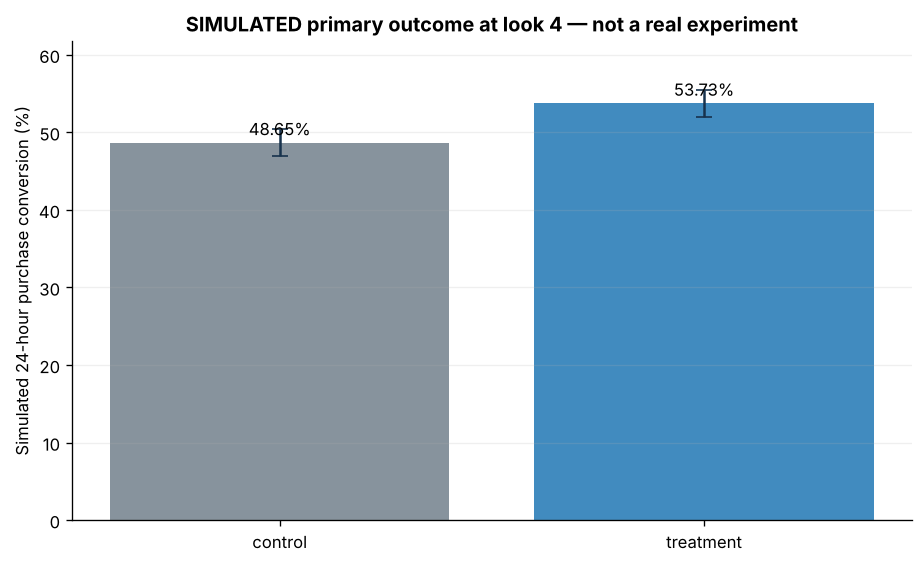

,Metric,Difference,Interval,Rule
0,24-hour conversion (primary),+5.08 pp,+2.52 to +7.64 pp (repeated CI),z 4.01 vs boundary 2.02
1,Revenue per eligible user (secondary),$+4.26,$+2.13 to $+6.39 (95%),Secondary; no automatic ship rule
2,Payment-error rate (guardrail),+0.54 pp,-0.45 to +1.54 pp (repeated CI),Upper bound below +1.50 pp: False


In [14]:
final_window = simulated.iloc[: stopping["enrolled"]]
primary_summary = final_window.groupby("variant", as_index=False).agg(
    assigned_users=("synthetic_unit_id", "count"),
    converted_users=("converted_within_24h", "sum"),
)
primary_summary["conversion_rate"] = (
    primary_summary["converted_users"] / primary_summary["assigned_users"]
)
interval_rows = [
    wilson_interval(row.converted_users, row.assigned_users)
    for row in primary_summary.itertuples()
]
primary_summary["ci95_lower"] = [value[0] for value in interval_rows]
primary_summary["ci95_upper"] = [value[1] for value in interval_rows]
primary_display = primary_summary.copy()
for column in ["conversion_rate", "ci95_lower", "ci95_upper"]:
    primary_display[column] = primary_display[column].map(
        lambda value: f"{value:.2%}"
    )
display(primary_display)

fig, ax = plt.subplots(figsize=(7.8, 4.8))
rates = primary_summary["conversion_rate"] * 100
lower_error = (
    primary_summary["conversion_rate"] - primary_summary["ci95_lower"]
) * 100
upper_error = (
    primary_summary["ci95_upper"] - primary_summary["conversion_rate"]
) * 100
bars = ax.bar(
    primary_summary["variant"],
    rates,
    color=[GREY, BLUE],
    alpha=0.9,
)
ax.errorbar(
    primary_summary["variant"],
    rates,
    yerr=[lower_error, upper_error],
    fmt="none",
    ecolor=NAVY,
    capsize=5,
)
ax.set_ylabel("Simulated 24-hour purchase conversion (%)")
ax.set_title(
    f"SIMULATED primary outcome at look {stopping_look} "
    "— not a real experiment"
)
ax.grid(axis="y", alpha=0.2)
for bar, value in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1.0,
        f"{value:.2f}%",
        ha="center",
    )
ax.set_ylim(0, max(rates) + 8)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "08_simulated_primary_effect.png",
    bbox_inches="tight",
)
plt.show()

control_revenue = final_window.loc[
    final_window["variant"] == "control", "purchase_revenue_usd"
]
treatment_revenue = final_window.loc[
    final_window["variant"] == "treatment", "purchase_revenue_usd"
]
revenue_effect = treatment_revenue.mean() - control_revenue.mean()
revenue_standard_error = sqrt(
    treatment_revenue.var(ddof=1) / len(treatment_revenue)
    + control_revenue.var(ddof=1) / len(control_revenue)
)
revenue_lower = revenue_effect - Z_95 * revenue_standard_error
revenue_upper = revenue_effect + Z_95 * revenue_standard_error
primary_p_value = 2 * (1 - NormalDist().cdf(abs(stopping["z"])))
display(
    pd.DataFrame(
        [
            {
                "Metric": "24-hour conversion (primary)",
                "Difference": f"{stopping['effect'] * 100:+.2f} pp",
                "Interval": (
                    f"{stopping['effect_lower'] * 100:+.2f} to "
                    f"{stopping['effect_upper'] * 100:+.2f} pp "
                    "(repeated CI)"
                ),
                "Rule": (
                    f"z {stopping['z']:.2f} vs boundary "
                    f"{stopping['boundary']:.2f}"
                ),
            },
            {
                "Metric": "Revenue per eligible user (secondary)",
                "Difference": f"${revenue_effect:+.2f}",
                "Interval": (
                    f"${revenue_lower:+.2f} to ${revenue_upper:+.2f} "
                    "(95%)"
                ),
                "Rule": "Secondary; no automatic ship rule",
            },
            {
                "Metric": "Payment-error rate (guardrail)",
                "Difference": f"{stopping['error_effect'] * 100:+.2f} pp",
                "Interval": (
                    f"{stopping['error_lower'] * 100:+.2f} to "
                    f"{stopping['error_upper'] * 100:+.2f} pp "
                    "(repeated CI)"
                ),
                "Rule": (
                    "Upper bound below "
                    f"+{PAYMENT_ERROR_MARGIN * 100:.2f} pp: "
                    f"{stopping['error_upper'] < PAYMENT_ERROR_MARGIN}"
                ),
            },
        ]
    )
)

## 12. Design contract checks

These checks gate the build. They test properties of the design,
which are deterministic for the fixed seeds, not the outcome of the
single simulated draw: a real test can fail to ship a good change, and
the plan accepts that risk about 20% of the time.

In [15]:
contract = pd.DataFrame(
    [
        {
            "Design contract": "Every synthetic row is marked simulated",
            "Value": f"{len(simulated):,} rows",
            "Pass": bool(simulated["is_simulated"].all()),
        },
        {
            "Design contract": "Assignment passes the SRM gate at every look read",
            "Value": (
                "min p = "
                f"{min(row['srm_p_value'] for row in look_results):.3f}"
            ),
            "Pass": all(
                row["srm_p_value"] >= 0.001 for row in look_results
            ),
        },
        {
            "Design contract": (
                "Original rule ships a true +5 pp lift less than 40% "
                "of the time"
            ),
            "Value": f"{original_at_mde['ship']:.1%}",
            "Pass": original_at_mde["ship"] < 0.40,
        },
        {
            "Design contract": (
                "Final plan ships a true +5 pp lift at least 80% of "
                "the time"
            ),
            "Value": f"{plan_scenarios['mde']['ship']:.1%}",
            "Pass": plan_scenarios["mde"]["ship"] >= 0.80,
        },
        {
            "Design contract": (
                "Final plan ships a no-effect change at most 2.5% of "
                "the time"
            ),
            "Value": f"{plan_scenarios['no_effect']['ship']:.2%}",
            "Pass": plan_scenarios["no_effect"]["ship"] <= 0.025,
        },
        {
            "Design contract": (
                "Final plan ships a +5 pp change that raises payment "
                "errors by the full margin at most 3% of the time"
            ),
            "Value": f"{plan_scenarios['mde_with_harm']['ship']:.2%}",
            "Pass": plan_scenarios["mde_with_harm"]["ship"] <= 0.03,
        },
        {
            "Design contract": (
                "Four O'Brien-Fleming looks keep the overall "
                "false-positive rate at 5%"
            ),
            "Value": f"{obf_false_positive_rate:.2%}",
            "Pass": abs(obf_false_positive_rate - ALPHA) <= 0.005,
        },
    ]
)
display(contract)
assert contract["Pass"].all()

decision_reasons = {
    "Ship": (
        f"The primary z-statistic of {stopping['z']:.2f} crossed the "
        f"boundary of {stopping['boundary']:.2f}, and the payment-error "
        f"upper bound of {stopping['error_upper'] * 100:+.2f} pp cleared "
        "the margin."
    ),
    "Stop for harm": (
        "The payment-error lower bound of "
        f"{stopping['error_lower'] * 100:+.2f} pp shows harm."
    ),
    "Stop for futility": (
        "The observed lift was not positive at the halfway look."
    ),
    "Do not ship: guardrail not cleared": (
        f"The lift is significant (z {stopping['z']:.2f} against a "
        f"boundary of {stopping['boundary']:.2f}), but the "
        "payment-error upper bound of "
        f"{stopping['error_upper'] * 100:+.2f} pp does not clear the "
        f"+{PAYMENT_ERROR_MARGIN * 100:.2f} pp margin, so the "
        "pre-registered rule does not ship. A true +5.00 pp lift with "
        "no payment harm ends this way "
        f"{plan_scenarios['mde']['guardrail_block']:.0%} of the time; "
        "the remedy is a margin decision by Payments, not a re-read of "
        "the data."
    ),
    "Do not ship: lift not significant": (
        f"The z-statistic of {stopping['z']:.2f} stayed below the "
        f"final boundary of {stopping['boundary']:.2f}."
    ),
    "Stop: sample-ratio mismatch": (
        "Assignment failed the sample-ratio check."
    ),
}
early_stop_note = (
    " Estimates from an early stop tend to overstate the true lift."
    if stopping_look < PLANNED_LOOKS
    else ""
)
display(
    Markdown(
        "> **SIMULATION-ONLY INTERPRETATION**\n>\n"
        f"> The seeded draw reached **{simulated_decision}** at look "
        f"{stopping_look} of {PLANNED_LOOKS}, with a "
        f"{stopping['effect'] * 100:+.2f} pp estimated lift. "
        f"{decision_reasons[simulated_decision]} Under the plan, a "
        "true +5.00 pp lift ships "
        f"{plan_scenarios['mde']['ship']:.0%} of the time, so this "
        f"outcome is consistent with the design.{early_stop_note} "
        "This is not a real product result."
    )
)

,Design contract,Value,Pass
0,Every synthetic row is marked simulated,"6,216 rows",True
1,Assignment passes the SRM gate at every look read,min p = 0.282,True
2,Original rule ships a true +5 pp lift less than 40% of the time,28.6%,True
3,Final plan ships a true +5 pp lift at least 80% of the time,80.1%,True
4,Final plan ships a no-effect change at most 2.5% of the time,1.95%,True
5,Final plan ships a +5 pp change that raises payment errors by the full margin at most 3% of the ...,2.35%,True
6,Four O'Brien-Fleming looks keep the overall false-positive rate at 5%,4.98%,True


> **SIMULATION-ONLY INTERPRETATION**
>
> The seeded draw reached **Do not ship: guardrail not cleared** at look 4 of 4, with a +5.08 pp estimated lift. The lift is significant (z 4.01 against a boundary of 2.02), but the payment-error upper bound of +1.54 pp does not clear the +1.50 pp margin, so the pre-registered rule does not ship. A true +5.00 pp lift with no payment harm ends this way 14% of the time; the remedy is a margin decision by Payments, not a re-read of the data. Under the plan, a true +5.00 pp lift ships 80% of the time, so this outcome is consistent with the design. This is not a real product result.

## 13. Launch gates and limitations

**Before a real experiment**

1. Implement and validate one sticky assignment/exposure signal; repeated
   `begin_checkout` events must not re-randomize or restart the window.
2. Run shadow assignment or an A/A check to measure current unique
   eligible users per day and confirm sticky exposure.
3. Measure the real payment-error rate; the guardrail sizing assumes 4%.
4. Obtain product and finance agreement that +5.00 pp is the smallest
   effect worth detecting, and payments/engineering agreement on the
   guardrail margin (section 9).
5. Freeze the analysis plan, the four look dates, and the boundaries
   before any treatment outcome is visible.

**Limitations**

- The 48.02% baseline is session-grain and same-session, while the test
  is user-randomized with a 24-hour window.
- Historical checkout sessions overstate unique-user throughput when a
  user has multiple eligible sessions, so every duration is optimistic.
- The historical source records multiple `begin_checkout` events in
  92.75% of eligible sessions, so it cannot serve as assignment logging.
- The source is an obfuscated 2020–2021 sample, not current production
  traffic.
- Sample sizes and operating characteristics rely on normal
  approximations and simulation with independent randomized units,
  equal allocation, and stable rates. Refund/cancellation and
  checkout-time guardrails are not yet sized.
- After an early stop the point estimate tends to overstate the true
  lift; report it with the repeated confidence interval.
- Revenue is gross rather than profit; no engineering cost or margin
  data are available.
- The synthetic draw assumes a true +5.00 pp lift. It cannot validate
  the intervention.

The real experiment remains **blocked on experiment-specific telemetry
and stakeholder sign-off**, even though the statistical workflow is
reproducible.

## 14. Export the design summary

The dashboard and decision memo read their experiment numbers from this
file instead of copying them by hand.

In [16]:
def rounded(value, digits=6):
    return round(float(value), digits)


design_summary = {
    "generated_by": "scripts/build_ab_test_notebook.py",
    "evidence_value": "planning_and_simulation_only",
    "inputs": {
        "checkout_sessions": checkout_sessions,
        "purchase_after_checkout_sessions": purchase_after_checkout_sessions,
        "historical_baseline_proxy": rounded(historical_baseline_proxy, 10),
        "observed_calendar_days": observed_days,
        "daily_checkout_session_proxy": rounded(daily_checkout_session_proxy),
        "average_order_value_usd": rounded(average_order_value, 4),
    },
    "assumptions": {
        "alpha": ALPHA,
        "target_power": TARGET_POWER,
        "planned_mde": PLANNED_MDE,
        "operational_buffer": OPERATIONAL_BUFFER,
        "payment_error_base_rate": PAYMENT_ERROR_BASE_RATE,
        "payment_error_margin": PAYMENT_ERROR_MARGIN,
        "planned_looks": PLANNED_LOOKS,
        "boundary_method": "O'Brien-Fleming",
        "futility_rule": "Stop at the halfway look if the observed lift is zero or negative (non-binding)",
        "harm_rule": "Stop at any look if the payment-error lower bound is above zero",
        "decision_seed": DECISION_SEED,
        "decision_repetitions": DECISION_REPETITIONS,
    },
    "primary_only": {
        "core_per_arm": core_n_per_arm,
        "enrollment_per_arm": primary_only_per_arm,
        "enrollment_total": primary_only_total,
        "proxy_weeks": rounded(primary_only_weeks, 4),
    },
    "original_plan_audit": {
        "core_per_arm": core_n_per_arm,
        "enrollment_total": primary_only_total,
        "probability_primary_interval_at_mde": rounded(original_at_mde["primary_interval"]),
        "probability_point_estimate_at_mde": rounded(original_at_mde["point_estimate"]),
        "probability_guardrail_at_mde": rounded(original_at_mde["guardrail"]),
        "ship_probability_at_mde": rounded(original_at_mde["ship"]),
        "ship_probability_at_mde_without_point_hurdle": rounded(corrected_at_original_n["ship"]),
        "ship_probability_no_effect": rounded(original_no_effect["ship"]),
    },
    "fixed_design": {
        "core_per_arm": fixed_core_per_arm,
        "ship_probability_at_mde": rounded(fixed_check["ship"]),
    },
    "plan": {
        "core_per_arm": plan_core_per_arm,
        "enrollment_per_arm": plan_enrollment_per_arm,
        "enrollment_total": plan_enrollment_total,
        "max_proxy_weeks": rounded(plan_max_weeks, 4),
        "expected_proxy_weeks_if_effective": rounded(
            plan_scenarios["mde"]["expected_fraction"] * plan_max_weeks, 4
        ),
        "expected_proxy_weeks_if_no_effect": rounded(
            plan_scenarios["no_effect"]["expected_fraction"] * plan_max_weeks, 4
        ),
        "ship_probability_at_mde": rounded(plan_scenarios["mde"]["ship"]),
        "ship_probability_half_mde": rounded(plan_scenarios["half_mde"]["ship"]),
        "ship_probability_no_effect": rounded(plan_scenarios["no_effect"]["ship"]),
        "ship_probability_harmful_change": rounded(plan_scenarios["mde_with_harm"]["ship"]),
        "harm_stop_probability_harmful_change": rounded(plan_scenarios["mde_with_harm"]["harm_stop"]),
        "harm_stop_probability_no_harm": rounded(plan_scenarios["mde"]["harm_stop"]),
        "guardrail_block_probability_at_mde": rounded(plan_scenarios["mde"]["guardrail_block"]),
        "no_significant_lift_probability_at_mde": rounded(plan_scenarios["mde"]["no_significant_lift"]),
        "futility_stop_probability_no_effect": rounded(plan_scenarios["no_effect"]["futility_stop"]),
        "overall_false_positive_rate": rounded(obf_false_positive_rate, 4),
    },
    "boundaries": [
        {
            "look": index,
            "information_fraction": rounded(fraction, 4),
            "enrolled_per_arm": round(plan_enrollment_per_arm * fraction),
            "enrolled_total": round(plan_enrollment_total * fraction),
            "proxy_week": rounded(plan_max_weeks * fraction, 4),
            "z_boundary": rounded(bound, 4),
            "nominal_two_sided_p": rounded(2 * (1 - NormalDist().cdf(bound)), 6),
        }
        for index, (fraction, bound) in enumerate(
            zip(plan_look_fractions, plan_bounds), start=1
        )
    ],
    "operating_characteristics": [
        *[
            {
                "design": "original_plan",
                "true_lift_pp": rounded(lift * 100, 2),
                "payment_harm_pp": 0.0,
                "ship_probability": rounded(probability),
                "expected_proxy_weeks": rounded(primary_only_weeks, 4),
            }
            for lift, probability in zip(AUDIT_LIFTS, original_curve)
        ],
        *[
            {
                "design": "final_plan",
                "true_lift_pp": rounded(lift * 100, 2),
                "payment_harm_pp": 0.0,
                "ship_probability": rounded(result["ship"]),
                "expected_proxy_weeks": rounded(
                    result["expected_fraction"] * plan_max_weeks, 4
                ),
            }
            for lift, result in zip(AUDIT_LIFTS, plan_curve)
        ],
        {
            "design": "final_plan",
            "true_lift_pp": rounded(PLANNED_MDE * 100, 2),
            "payment_harm_pp": rounded(PAYMENT_ERROR_MARGIN * 100, 2),
            "ship_probability": rounded(plan_scenarios["mde_with_harm"]["ship"]),
            "expected_proxy_weeks": rounded(
                plan_scenarios["mde_with_harm"]["expected_fraction"] * plan_max_weeks, 4
            ),
        },
    ],
    "margin_tradeoff": [
        {
            "margin_pp": rounded(row.margin * 100, 2),
            "guardrail_power_at_original_core": rounded(row.guardrail_power_original_n),
            "fixed_core_per_arm": int(row.fixed_core_per_arm),
            "sequential_core_per_arm": int(row.sequential_core_per_arm),
            "enrollment_total": int(row.enrollment_total),
            "max_proxy_weeks": rounded(row.max_weeks, 4),
            "expected_proxy_weeks_if_effective": rounded(row.expected_weeks_if_effective, 4),
        }
        for row in margin_tradeoff.itertuples()
    ],
    "peeking": [
        {
            "monitoring": label,
            "looks": looks,
            "false_positive_rate": rounded(rate),
        }
        for label, looks, rate in [
            ("One read at the end", 1, peeking_rates[1]),
            ("Weekly reads, unadjusted", weekly_looks, peeking_rates[weekly_looks]),
            ("Daily reads, unadjusted", daily_looks, peeking_rates[daily_looks]),
            ("Four planned reads, O'Brien-Fleming", PLANNED_LOOKS, obf_false_positive_rate),
        ]
    ],
    "planner": {
        "inflation_factors": {
            str(looks): {
                f"{power:.2f}": rounded(factor, 5)
                for power, factor in factors.items()
            }
            for looks, factors in inflation_table.items()
        },
        "unadjusted_false_positive_rates": {
            str(looks): rounded(unadjusted_false_positive_rate(looks))
            for looks in PLANNER_LOOKS
        },
    },
    "simulated_example": {
        "is_simulated": True,
        "seed": SIMULATION_SEED,
        "true_lift_pp": rounded(TRUE_SIMULATED_LIFT * 100, 2),
        "stopping_look": stopping_look,
        "decision": simulated_decision,
        "enrolled_users": stopping["enrolled"],
        "control_users": stopping["control_users"],
        "treatment_users": stopping["treatment_users"],
        "control_conversion_rate": rounded(stopping["control_rate"]),
        "treatment_conversion_rate": rounded(stopping["treatment_rate"]),
        "estimated_difference_pp": rounded(stopping["effect"] * 100, 4),
        "interval_lower_pp": rounded(stopping["effect_lower"] * 100, 4),
        "interval_upper_pp": rounded(stopping["effect_upper"] * 100, 4),
        "z_statistic": rounded(stopping["z"], 4),
        "z_boundary": rounded(stopping["boundary"], 4),
        "nominal_two_sided_p_value": rounded(primary_p_value, 6),
        "srm_p_value": rounded(stopping["srm_p_value"], 4),
        "revenue_per_eligible_user_difference_usd": rounded(revenue_effect, 4),
        "payment_error_difference_pp": rounded(stopping["error_effect"] * 100, 4),
        "payment_error_upper_pp": rounded(stopping["error_upper"] * 100, 4),
        "evidence_value": "demonstration_only",
    },
}
summary_path = OUTPUT_DIR / "experiment_design_summary.json"
summary_path.write_text(
    json.dumps(design_summary, indent=2) + "\n",
    encoding="utf-8",
)
print(f"Wrote {summary_path.relative_to(ROOT)}")

Wrote notebooks/outputs/experiment_design_summary.json
